In [1]:
import os
import numpy as np
import cv2
from glob import glob
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.layers import Conv2D, Input, Concatenate, MaxPooling2D, Conv2DTranspose
from tensorflow.keras.models import Model
import numpy as np
import tensorflow as tf
from segmentation_models import Unet
from segmentation_models.losses import CategoricalCELoss
from segmentation_models.metrics import IOUScore

Segmentation Models: using `keras` framework.


In [27]:
def load_data(images_path):
    images = sorted(glob(os.path.join(images_path, "*.jpg")))
    return images

In [16]:
def preprocess_data(images, masks_folders, image_size):
    all_images = []
    all_combined_masks = []

    for img_path in images:
        img = cv2.imread(img_path)
        img = cv2.resize(img, (image_size, image_size))
        all_images.append(img)

    for img_path in images:
        combined_mask = np.zeros((image_size, image_size), dtype=np.uint8)
        img_name = os.path.splitext(os.path.basename(img_path))[0]
        for j, folder in enumerate(masks_folders):
            folder_name = os.path.basename(folder)
            mask_path = os.path.join(folder, f"{img_name}_{folder_name}.tif")
            if os.path.exists(mask_path):
                mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
                mask = cv2.resize(mask, (image_size, image_size))
                mask = np.where(mask > 0, j + 1, 0)  # Set different pixel values for each type of lesion
                combined_mask = np.maximum(combined_mask, mask)  # Combine all masks
        all_combined_masks.append(combined_mask)

    all_images = np.array(all_images, dtype=np.float32)
    all_combined_masks = np.array(all_combined_masks, dtype=np.float32)
    return all_images, all_combined_masks



In [28]:
train_images_path = 'F:/Datasets/IDRID/U-net segmentation/A. Segmentation/train_images'
train_masks_folders = [
    'F:/Datasets/IDRID/U-net segmentation/A. Segmentation/train_masks/EX',
    'F:/Datasets/IDRID/U-net segmentation/A. Segmentation/train_masks/HE',
    'F:/Datasets/IDRID/U-net segmentation/A. Segmentation/train_masks/MA',
    'F:/Datasets/IDRID/U-net segmentation/A. Segmentation/train_masks/OD',
    'F:/Datasets/IDRID/U-net segmentation/A. Segmentation/train_masks/SE',
]

test_images_path = 'F:/Datasets/IDRID/U-net segmentation/A. Segmentation/test_images'
test_masks_folders = [
    'F:/Datasets/IDRID/U-net segmentation/A. Segmentation/test_masks/EX',
    'F:/Datasets/IDRID/U-net segmentation/A. Segmentation/test_masks/HE',
    'F:/Datasets/IDRID/U-net segmentation/A. Segmentation/test_masks/MA',
    'F:/Datasets/IDRID/U-net segmentation/A. Segmentation/test_masks/OD',
    'F:/Datasets/IDRID/U-net segmentation/A. Segmentation/test_masks/SE',
]

train_images = load_data(train_images_path)
test_images = load_data(test_images_path)

X_train, y_train = preprocess_data(train_images, train_masks_folders, 512)
X_test, y_test = preprocess_data(test_images, test_masks_folders, 512)

In [18]:
X_train = X_train / 255.0
X_test = X_test / 255.0

# Convert the masks to one-hot encoding
y_train_one_hot = tf.keras.utils.to_categorical(y_train, num_classes=6)
y_test_one_hot = tf.keras.utils.to_categorical(y_test, num_classes=6)

In [20]:
model = Unet('efficientnetb1', classes=6, activation='softmax', encoder_weights='imagenet')

In [21]:
loss = CategoricalCELoss()
iou_score = IOUScore()

# Compile the model
model.compile(optimizer='adam', loss=loss, metrics=[iou_score])

In [22]:
history = model.fit(
    X_train, 
    y_train_one_hot, 
    batch_size=3, 
    epochs=30, 
    validation_data=(X_test, y_test_one_hot)
)

Epoch 1/30
18/18 [==============================] - 23s 629ms/step - loss: 0.1842 - iou_score: 0.0765 - val_loss: 2.5125 - val_iou_score: 0.0055
Epoch 2/30
18/18 [==============================] - 9s 513ms/step - loss: 0.0480 - iou_score: 0.1787 - val_loss: 0.8341 - val_iou_score: 0.0380
Epoch 3/30
18/18 [==============================] - 9s 512ms/step - loss: 0.0243 - iou_score: 0.2403 - val_loss: 0.1672 - val_iou_score: 0.1201
Epoch 4/30
18/18 [==============================] - 9s 519ms/step - loss: 0.0194 - iou_score: 0.2739 - val_loss: 0.0725 - val_iou_score: 0.1662
Epoch 5/30
18/18 [==============================] - 9s 517ms/step - loss: 0.0176 - iou_score: 0.2899 - val_loss: 0.0685 - val_iou_score: 0.1765
Epoch 6/30
18/18 [==============================] - 9s 505ms/step - loss: 0.0159 - iou_score: 0.3052 - val_loss: 0.0460 - val_iou_score: 0.1981
Epoch 7/30
18/18 [==============================] - 9s 504ms/step - loss: 0.0148 - iou_score: 0.3188 - val_loss: 0.0320 - val_iou_score

27/27 [==============================] - 2s 59ms/step


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


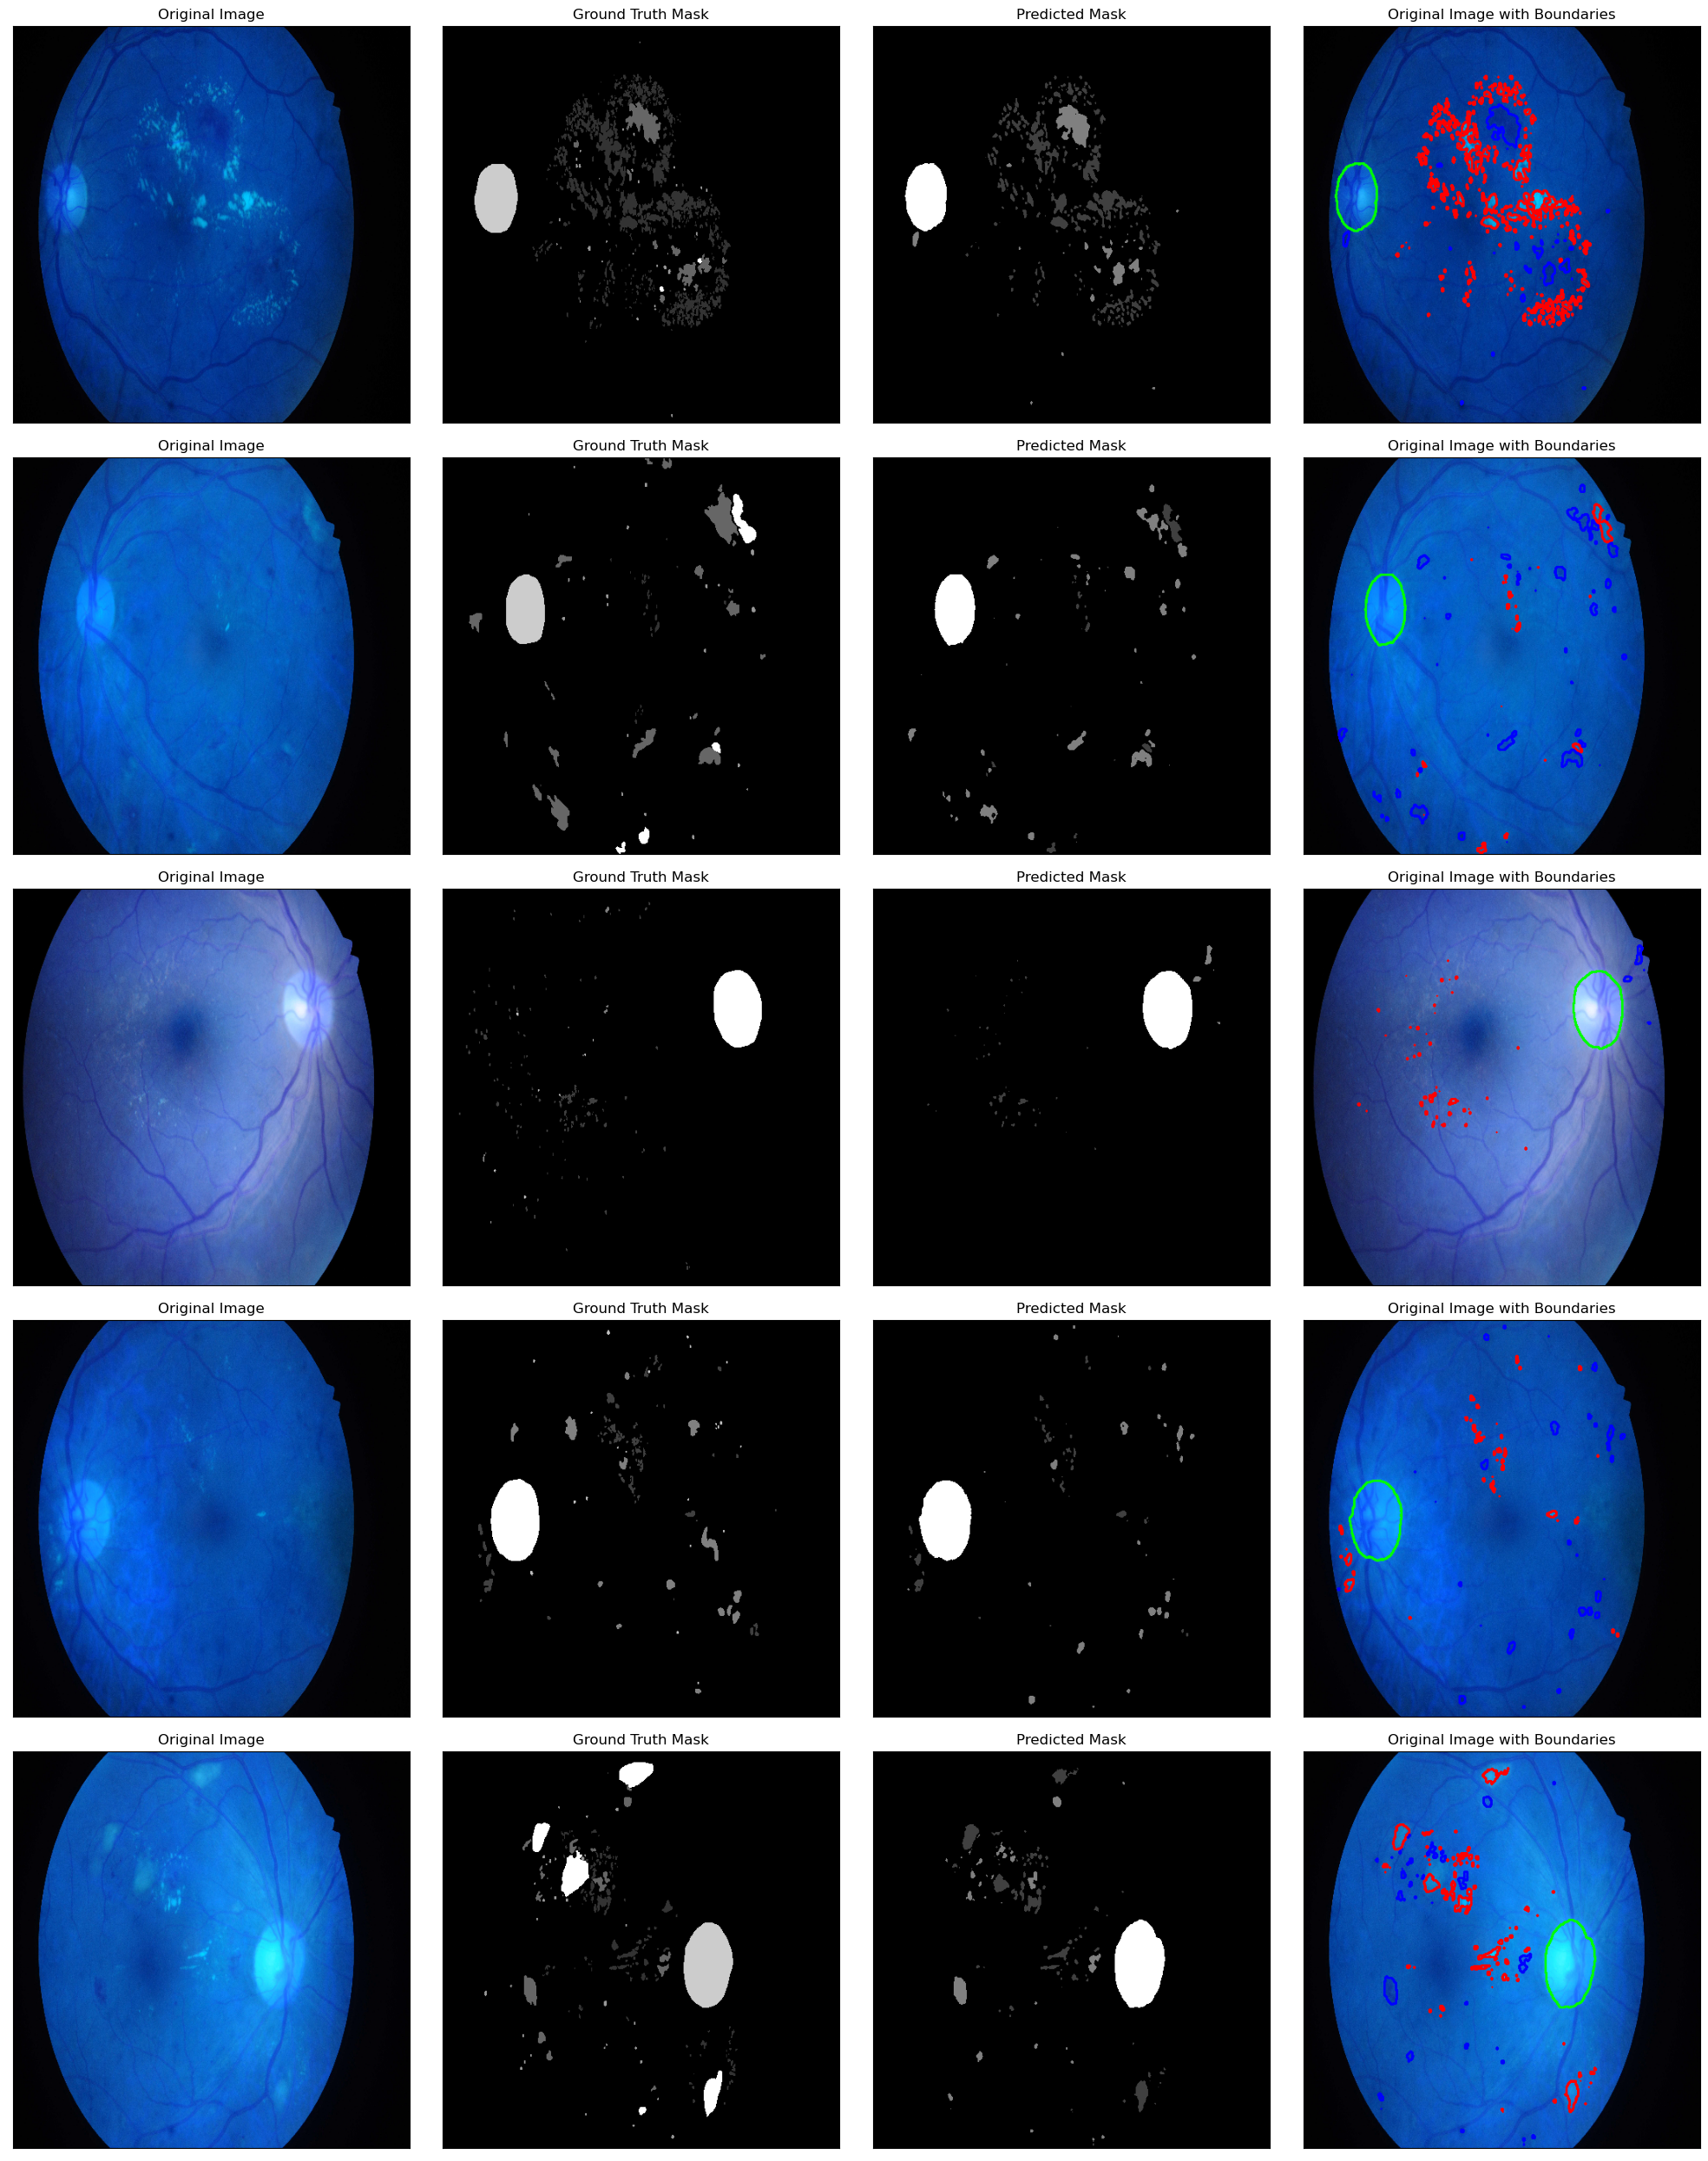

In [26]:
import matplotlib.pyplot as plt
import cv2

# Predict masks on test data
y_pred = model.predict(X_test, batch_size=1)

# Convert predictions to one-hot encoded masks
y_pred_argmax = np.argmax(y_pred, axis=-1)

# Visualize results
n = 5  # Number of images to visualize
fig, axes = plt.subplots(n, 4, figsize=(20, 5 * n))

# Define colors for each class
colors = [(0, 255, 0), (255, 0, 0), (0, 0, 255), (255, 255, 0)]  # Green, Red, Blue, Yellow

for i in range(n):
    axes[i, 0].imshow(X_test[i])
    axes[i, 0].set_title('Original Image')
    axes[i, 1].imshow(y_test[i], cmap='gray')
    axes[i, 1].set_title('Ground Truth Mask')
    axes[i, 2].imshow(y_pred_argmax[i], cmap='gray')
    axes[i, 2].set_title('Predicted Mask')

    # Create a copy of the original image to overlay the boundaries
    overlay = X_test[i].copy()

    for j in range(1, y_pred_argmax.shape[-1]):  # Loop through classes (skip background)
        # Find contours and draw boundaries for each class
        contours, _ = cv2.findContours((y_pred_argmax[i] == j).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(overlay, contours, -1, colors[j % len(colors)], 2)

    axes[i, 3].imshow(overlay)
    axes[i, 3].set_title('Original Image with Boundaries')

    # Remove axis ticks
    for ax in axes[i]:
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()


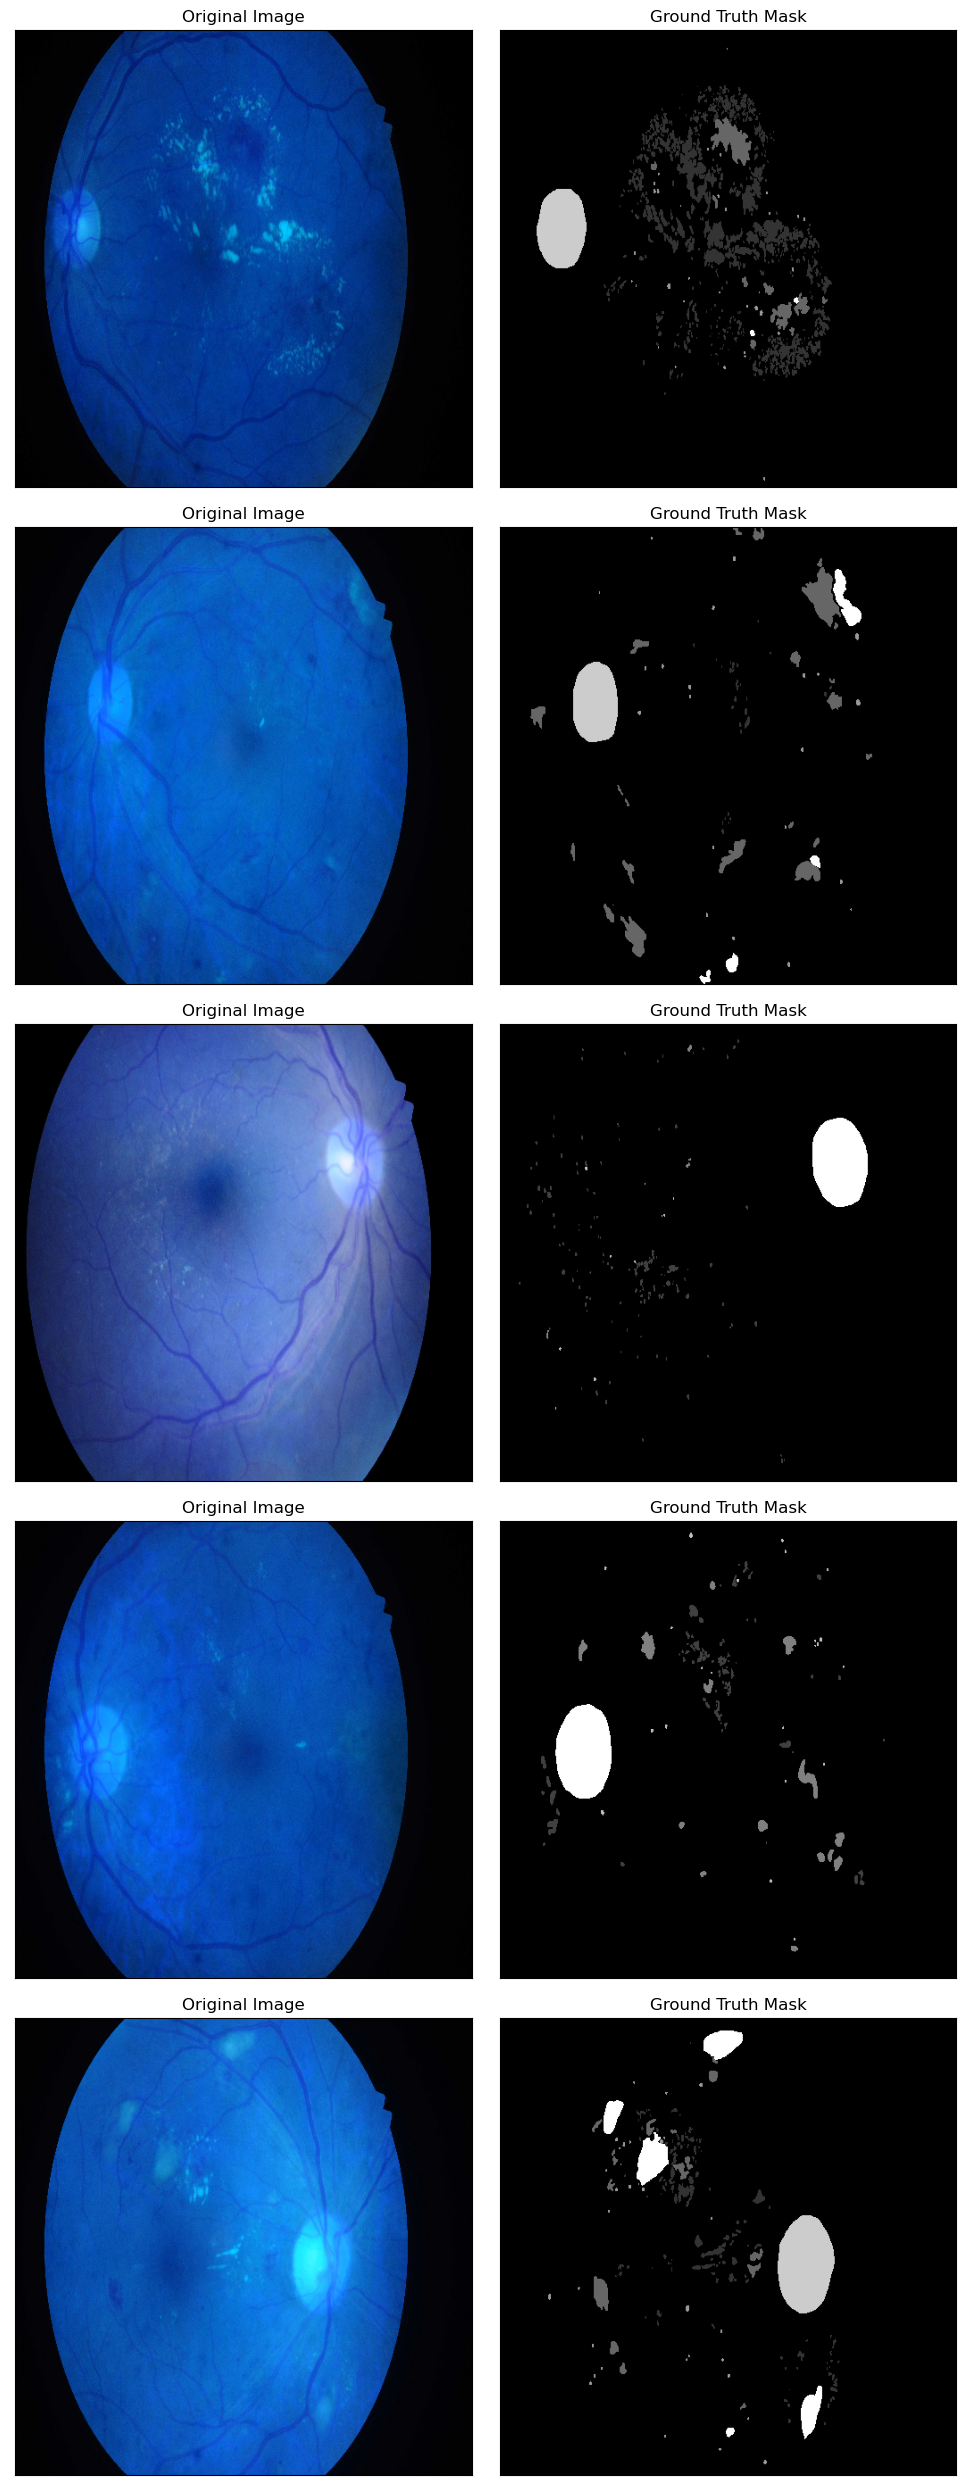

In [19]:
def visualize_ground_truth(X, y, n=5):
    fig, axes = plt.subplots(n, 2, figsize=(10, 5 * n))

    for i in range(n):
        axes[i, 0].imshow(X[i])
        axes[i, 0].set_title('Original Image')
        axes[i, 1].imshow(y[i], cmap='gray')
        axes[i, 1].set_title('Ground Truth Mask')

        # Remove axis ticks
        for ax in axes[i]:
            ax.set_xticks([])
            ax.set_yticks([])

    plt.tight_layout()
    plt.show()

# Visualize ground truth masks for test data
visualize_ground_truth(X_test, y_test, n=5)